# Unsupervised PCA-Space Clustering of US City Level-Set Persistence

This notebook clusters the samples in `figs/test_us_cities/manually_filtered_01` using the H1 persistence information produced by the level-set filtration.

The folder contains both persistence diagrams (`h1_pairs.csv`) and precomputed H1 persistence landscapes (`persistence_landscape_h1.npz`). The main clustering below uses persistence landscapes because they give fixed-length vectors, are stable summaries of persistence diagrams, and can be clustered with standard methods. The raw landscapes in this dataset are evaluated on sample-specific `x_grid` ranges, so the notebook first resamples every landscape onto a shared normalized coordinate in `[0, 1]` before comparing samples.

Workflow:

1. Load H1 diagrams and landscape arrays.
2. Parse city and morphology labels from folder names for later validation only.
3. Normalize and resample landscapes onto a common grid.
4. Reduce the landscape vectors with PCA, then cluster into two groups with average-linkage hierarchical clustering in PCA space.
5. Visualize the PCA-space clusters with dendrogram, PCA, and t-SNE plots. t-SNE is used only for visualization.
6. Compare unsupervised clusters against the folder labels (`gridiron` versus `cul_de_sac`).
7. Save cluster assignments to `notebooks/cluster_us_city_persistence_landscapes_pca_space_assignments.csv`.


GPB - Variante recomendada: el clustering se hace en PCA y t-SNE solo se usa para visualizar.


In [3]:
from pathlib import Path
import os
import re
import warnings

# Keep matplotlib/IPython caches inside writable locations when running from a sandboxed environment.
os.environ.setdefault('MPLCONFIGDIR', '/tmp/mplconfig')
os.environ.setdefault('IPYTHONDIR', '/tmp/ipython')
os.environ.setdefault('LOKY_MAX_CPU_COUNT', '8')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform
from scipy.optimize import linear_sum_assignment
from scipy.stats import skew

from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score, confusion_matrix

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')

## 1. Load the Dataset

In [4]:
def find_levelset_root(start=Path.cwd()) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "processed_data").exists() and (candidate / "labeled_data").exists():
            return candidate
        nested = candidate / "levelset_urban_ph"
        if (nested / "processed_data").exists() and (nested / "labeled_data").exists():
            return nested
    raise FileNotFoundError(f"Could not find levelset_urban_ph from {start.resolve()}")

LEVELSET_ROOT = find_levelset_root()
NOTEBOOK_DIR = LEVELSET_ROOT / "notebooks_clustering"
DATA_DIR = LEVELSET_ROOT / "processed_data" / "test_us_cities" / "manually_filtered_01"
ASSIGNMENTS_OUT = NOTEBOOK_DIR / 'cluster_us_city_persistence_landscapes_pca_space_assignments.csv'

LABEL_RE = re.compile(r'(gridiron|cul_de_sac)')
CITY_RE = re.compile(r'^(.+?)_(gridiron|cul_de_sac)_\d+$')

def parse_sample_name(name: str):
    label_match = LABEL_RE.search(name)
    label = label_match.group(1) if label_match else 'unknown'
    city_match = CITY_RE.match(name)
    city = city_match.group(1) if city_match else name
    return city, label

def read_h1_pairs(path: Path) -> np.ndarray:
    # h1_pairs.csv files were written without a header. Coerce in case pandas sees unusual formatting.
    df = pd.read_csv(path, header=None)
    arr = df.iloc[:, :2].apply(pd.to_numeric, errors='coerce').dropna().to_numpy(float)
    arr = arr[np.isfinite(arr).all(axis=1)]
    arr = arr[arr[:, 1] >= arr[:, 0]]
    return arr

records = []
landscape_arrays = []
x_grids = []
diagrams = []

for sample_dir in sorted(DATA_DIR.iterdir()):
    if not sample_dir.is_dir():
        continue
    landscape_path = sample_dir / 'persistence_landscape_h1.npz'
    diagram_path = sample_dir / 'h1_pairs.csv'
    if not landscape_path.exists() or not diagram_path.exists():
        continue

    z = np.load(landscape_path)
    landscape = z['landscape_values'].astype(float)
    x_grid = z['x_grid'].astype(float)
    diagram = read_h1_pairs(diagram_path)
    city, label = parse_sample_name(sample_dir.name)

    records.append({
        'sample': sample_dir.name,
        'city': city,
        'label': label,
        'n_h1_pairs': len(diagram),
        'x_min': float(np.nanmin(x_grid)),
        'x_max': float(np.nanmax(x_grid)),
        'n_landscape_levels': landscape.shape[0],
        'landscape_resolution': landscape.shape[1],
    })
    landscape_arrays.append(landscape)
    x_grids.append(x_grid)
    diagrams.append(diagram)

meta = pd.DataFrame(records)
print(f'Loaded {len(meta)} samples from {DATA_DIR.resolve()}')
display(meta.head())
display(meta.groupby(['label', 'city']).size().rename('n_samples').reset_index())
display(meta[['n_h1_pairs', 'x_max']].describe())

Loaded 76 samples from /Users/gregorioperez/Documents/Maestria/Investigacion/levelset_urban/processed_data/test_us_cities/manually_filtered_01


,sample,city,label,n_h1_pairs,x_min,x_max,n_landscape_levels,landscape_resolution
0,cary_town_cul_de_sac_12,cary_town,cul_de_sac,238,0.0,124.9,50,500
1,cary_town_cul_de_sac_13,cary_town,cul_de_sac,181,0.0,109.1,50,500
2,cary_town_cul_de_sac_14,cary_town,cul_de_sac,143,0.0,51.3,50,500
3,cary_town_cul_de_sac_16,cary_town,cul_de_sac,190,0.0,108.5,50,500
4,cary_town_cul_de_sac_18,cary_town,cul_de_sac,97,0.0,95.9,50,500


,label,city,n_samples
0,cul_de_sac,cary_town,15
1,cul_de_sac,chandler,3
2,cul_de_sac,charleston,1
3,cul_de_sac,fort_collins,6
4,cul_de_sac,peachtree,5
5,cul_de_sac,philadelphia,4
6,cul_de_sac,santafe,3
7,gridiron,charleston,3
8,gridiron,fort_collins,2
9,gridiron,philadelphia,34


,n_h1_pairs,x_max
count,76.000000,76.000000
mean,76.894737,95.589474
std,51.740784,32.337176
min,18.000000,41.200000
25%,36.750000,70.575000
50%,64.500000,93.700000
75%,108.250000,114.650000
max,279.000000,191.400000


## 2. Build Comparable Landscape Features

The saved `flat_vector` arrays should not be compared directly because each sample has its own filtration coordinate range. This cell rescales each sample's `x_grid` by its maximum coordinate and interpolates each landscape level onto a common grid.

The clustering representation is:

1. H1 landscape values resampled to a common normalized filtration axis.
2. Landscape amplitudes divided by the sample's filtration span.
3. L2 normalization of each full landscape vector.

L2 normalization performed better here than column standardization because standardizing thousands of coordinates overweights sparse/noisy lower landscape levels and produced a singleton hierarchical split.

In [5]:
COMMON_RESOLUTION = 500
N_LEVELS = 50  # keep all available H1 landscape levels
common_grid = np.linspace(0.0, 1.0, COMMON_RESOLUTION)

def normalize_resample_landscape(landscape: np.ndarray, x_grid: np.ndarray, n_levels=N_LEVELS) -> np.ndarray:
    x = np.asarray(x_grid, dtype=float)
    y = np.asarray(landscape, dtype=float)
    if x.max() > x.min():
        x_norm = (x - x.min()) / (x.max() - x.min())
    else:
        x_norm = np.linspace(0.0, 1.0, len(x))

    levels = []
    for k in range(min(n_levels, y.shape[0])):
        levels.append(np.interp(common_grid, x_norm, y[k], left=0.0, right=0.0))

    while len(levels) < n_levels:
        levels.append(np.zeros_like(common_grid))

    # Divide amplitudes by the filtration span so city samples with different absolute scales remain comparable.
    span = max(float(x.max() - x.min()), 1e-12)
    return (np.vstack(levels) / span).ravel()

def diagram_summary_features(diagram: np.ndarray) -> dict:
    if diagram.size == 0:
        return {
            'pd_count': 0, 'pd_lifetime_mean': 0, 'pd_lifetime_std': 0, 'pd_lifetime_max': 0,
            'pd_lifetime_sum': 0, 'pd_lifetime_q25': 0, 'pd_lifetime_q50': 0, 'pd_lifetime_q75': 0,
            'pd_birth_mean': 0, 'pd_death_mean': 0, 'pd_lifetime_skew': 0,
        }
    birth = diagram[:, 0]
    death = diagram[:, 1]
    lifetime = death - birth
    return {
        'pd_count': len(lifetime),
        'pd_lifetime_mean': float(np.mean(lifetime)),
        'pd_lifetime_std': float(np.std(lifetime)),
        'pd_lifetime_max': float(np.max(lifetime)),
        'pd_lifetime_sum': float(np.sum(lifetime)),
        'pd_lifetime_q25': float(np.quantile(lifetime, 0.25)),
        'pd_lifetime_q50': float(np.quantile(lifetime, 0.50)),
        'pd_lifetime_q75': float(np.quantile(lifetime, 0.75)),
        'pd_birth_mean': float(np.mean(birth)),
        'pd_death_mean': float(np.mean(death)),
        'pd_lifetime_skew': float(skew(lifetime)) if len(lifetime) > 2 else 0.0,
    }

X_landscape = np.vstack([
    normalize_resample_landscape(landscape, x_grid)
    for landscape, x_grid in zip(landscape_arrays, x_grids)
])

X = normalize(X_landscape, norm='l2')

diagram_features = pd.DataFrame([diagram_summary_features(d) for d in diagrams])
meta_features = pd.concat([meta.reset_index(drop=True), diagram_features], axis=1)

print('Landscape feature matrix:', X_landscape.shape)
print('L2-normalized matrix:', X.shape)
display(meta_features.head())

Landscape feature matrix: (76, 25000)
L2-normalized matrix: (76, 25000)


,sample,city,label,n_h1_pairs,x_min,x_max,n_landscape_levels,landscape_resolution,pd_count,pd_lifetime_mean,pd_lifetime_std,pd_lifetime_max,pd_lifetime_sum,pd_lifetime_q25,pd_lifetime_q50,pd_lifetime_q75,pd_birth_mean,pd_death_mean,pd_lifetime_skew
0,cary_town_cul_de_sac_12,cary_town,cul_de_sac,238,0.0,124.9,50,500,238,4.136134,5.666891,50.5,984.4,1.8,2.70,3.800,4.273529,8.409664,5.242998
1,cary_town_cul_de_sac_13,cary_town,cul_de_sac,181,0.0,109.1,50,500,181,8.625414,10.328912,87.8,1561.2,2.2,4.70,11.300,12.800552,21.425967,3.524273
2,cary_town_cul_de_sac_14,cary_town,cul_de_sac,143,0.0,51.3,50,500,143,9.718182,9.696893,40.9,1389.7,2.2,6.00,12.700,11.452448,21.170629,1.565130
3,cary_town_cul_de_sac_16,cary_town,cul_de_sac,190,0.0,108.5,50,500,190,8.451579,11.409146,108.5,1605.8,2.1,5.05,9.975,11.013158,19.464737,4.560385
4,cary_town_cul_de_sac_18,cary_town,cul_de_sac,97,0.0,95.9,50,500,97,8.249485,10.585928,89.2,800.2,2.1,4.40,11.700,15.077320,23.326804,4.795957


## 3. PCA-Space Average-Linkage Hierarchical Clustering

This variant follows the recommended workflow: reduce the high-dimensional persistence landscape vectors with PCA, compute pairwise Euclidean distances in PCA space, then cut an average-linkage hierarchical tree into two clusters.

t-SNE is computed after the cluster labels are assigned and is used only as a visualization of the PCA-reduced representation. This avoids using t-SNE coordinates as the clustering space, since t-SNE is designed for local-neighborhood visualization and does not reliably preserve global distances.


In [6]:
# PCA denoises and reduces the sparse 25,000-dimensional landscape vectors.
n_pca_components = min(5, X.shape[0] - 1, X.shape[1])
pca = PCA(n_components=n_pca_components, random_state=42)
X_pca_full = pca.fit_transform(X)
X_pca2 = X_pca_full[:, :2]

# The final two-cluster hierarchical cut is built from Euclidean distances in PCA space.
condensed_pca_dist = pdist(X_pca_full, metric='euclidean')
D_pca = squareform(condensed_pca_dist)
Z = linkage(condensed_pca_dist, method='average')

cluster_labels = fcluster(Z, t=2, criterion='maxclust')
meta_features['cluster'] = cluster_labels - 1

sil_pca = silhouette_score(D_pca, meta_features['cluster'], metric='precomputed')
print(f'PCA-space silhouette score: {sil_pca:.3f}')
print('PCA explained variance ratio, first 5 components:')
print(np.round(pca.explained_variance_ratio_[:5], 3))
print(f'Cumulative explained variance, {n_pca_components} components: {pca.explained_variance_ratio_.sum():.3f}')

# t-SNE is computed only for visualization of the PCA-reduced landscape representation.
tsne = TSNE(
    n_components=2,
    perplexity=min(30, max(5, (len(meta_features) - 1) // 3)),
    init='pca',
    learning_rate='auto',
    random_state=42,
)
X_tsne = tsne.fit_transform(X_pca_full)

display(meta_features.groupby(['cluster', 'label']).size().unstack(fill_value=0))
display(meta_features.groupby(['cluster', 'city']).size().unstack(fill_value=0))


PCA-space silhouette score: 0.337
PCA explained variance ratio, first 5 components:
[0.379 0.148 0.113 0.071 0.047]
Cumulative explained variance, 5 components: 0.758


label,cul_de_sac,gridiron
cluster,,
0,6,30
1,31,9


city,cary_town,chandler,charleston,fort_collins,peachtree,philadelphia,santafe
cluster,,,,,,,
0,1,1,3,4,0,26,1
1,14,2,1,4,5,12,2


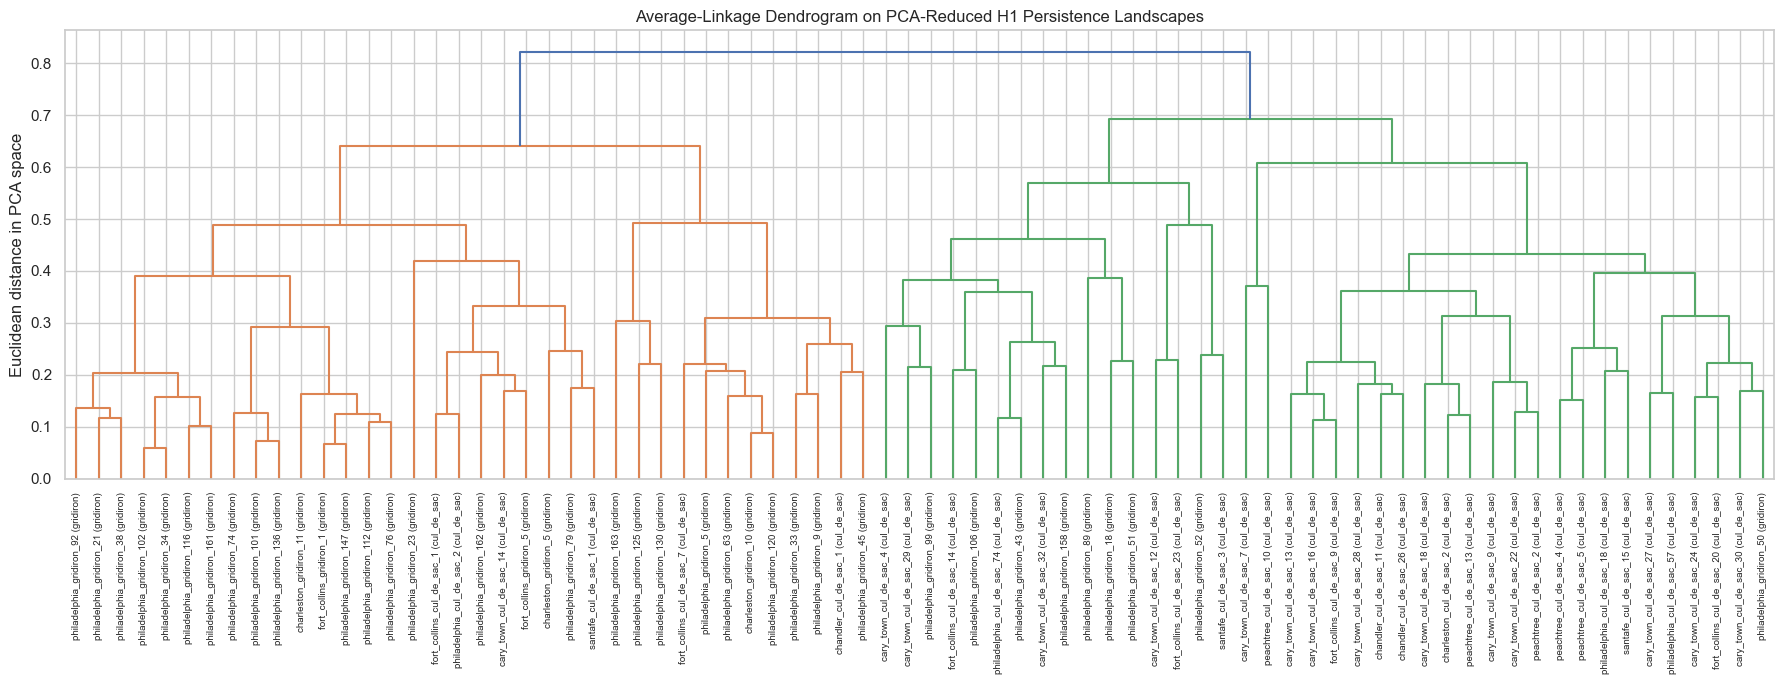

In [7]:
plt.figure(figsize=(18, 7))
leaf_labels = [f"{row.sample} ({row.label})" for row in meta_features.itertuples()]
dendrogram(
    Z,
    labels=leaf_labels,
    leaf_rotation=90,
    leaf_font_size=7,
    color_threshold=Z[-1, 2],
)
plt.title('Average-Linkage Dendrogram on PCA-Reduced H1 Persistence Landscapes')
plt.ylabel('Euclidean distance in PCA space')
plt.tight_layout()
plt.show()

## 4. PCA and t-SNE Visualizations

In [8]:
viz = meta_features.copy()
viz['pca1'] = X_pca2[:, 0]
viz['pca2'] = X_pca2[:, 1]
viz['tsne1'] = X_tsne[:, 0]
viz['tsne2'] = X_tsne[:, 1]

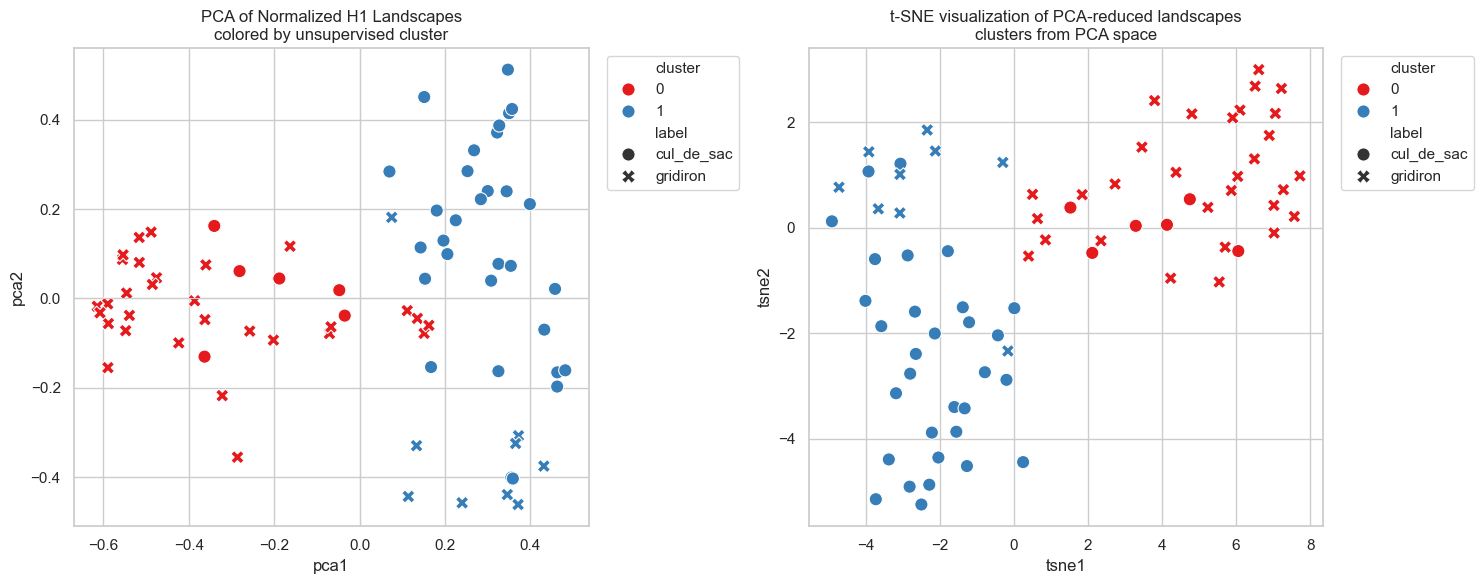

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=viz, x='pca1', y='pca2', hue='cluster', style='label', s=90,
    palette='Set1', ax=axes[0]
)
axes[0].set_title('PCA of Normalized H1 Landscapes\ncolored by unsupervised cluster')
axes[0].axhline(0, color='0.8', linewidth=0.8)
axes[0].axvline(0, color='0.8', linewidth=0.8)

sns.scatterplot(
    data=viz, x='tsne1', y='tsne2', hue='cluster', style='label', s=90,
    palette='Set1', ax=axes[1]
)
axes[1].set_title('t-SNE visualization of PCA-reduced landscapes\nclusters from PCA space')

for ax in axes:
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

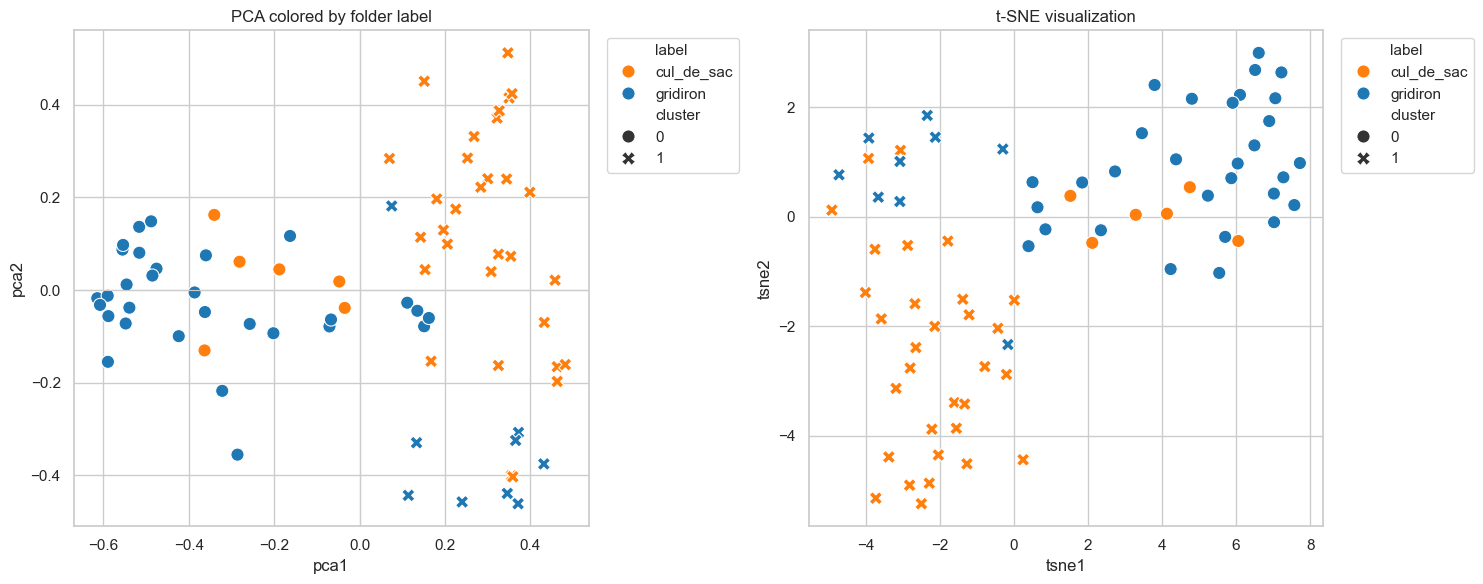

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=viz, x='pca1', y='pca2', hue='label', style='cluster', s=90,
    palette={'gridiron': '#1f77b4', 'cul_de_sac': '#ff7f0e'}, ax=axes[0]
)
axes[0].set_title('PCA colored by folder label')
axes[0].axhline(0, color='0.8', linewidth=0.8)
axes[0].axvline(0, color='0.8', linewidth=0.8)

sns.scatterplot(
    data=viz, x='tsne1', y='tsne2', hue='label', style='cluster', s=90,
    palette={'gridiron': '#1f77b4', 'cul_de_sac': '#ff7f0e'}, ax=axes[1]
)
axes[1].set_title('t-SNE visualization')

for ax in axes:
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

## 5. Compare Clusters Against Known Folder Labels

In [11]:
true_labels = meta_features['label'].map({'gridiron': 0, 'cul_de_sac': 1}).to_numpy()
pred = meta_features['cluster'].to_numpy()

ari = adjusted_rand_score(true_labels, pred)
nmi = normalized_mutual_info_score(true_labels, pred)

# Cluster IDs are arbitrary. Use Hungarian assignment to report best label-matched accuracy.
cm = confusion_matrix(true_labels, pred, labels=[0, 1])
row_ind, col_ind = linear_sum_assignment(-cm)
best_accuracy = cm[row_ind, col_ind].sum() / cm.sum()
cluster_to_label = {int(cluster): ['gridiron', 'cul_de_sac'][int(truth)] for truth, cluster in zip(row_ind, col_ind)}
meta_features['cluster_interpreted_as'] = meta_features['cluster'].map(cluster_to_label)
meta_features['matches_folder_label'] = meta_features['cluster_interpreted_as'] == meta_features['label']

print(f'Adjusted Rand Index: {ari:.3f}')
print(f'Normalized Mutual Information: {nmi:.3f}')
print(f'Best label-matched accuracy: {best_accuracy:.3f}')
print('Cluster interpretation:', cluster_to_label)

display(pd.DataFrame(cm, index=['true_gridiron', 'true_cul_de_sac'], columns=['cluster_0', 'cluster_1']))
display(meta_features.groupby(['cluster', 'cluster_interpreted_as', 'label']).size().rename('n').reset_index())

Adjusted Rand Index: 0.358
Normalized Mutual Information: 0.287
Best label-matched accuracy: 0.803
Cluster interpretation: {0: 'gridiron', 1: 'cul_de_sac'}


,cluster_0,cluster_1
true_gridiron,30,9
true_cul_de_sac,6,31


,cluster,cluster_interpreted_as,label,n
0,0,gridiron,cul_de_sac,6
1,0,gridiron,gridiron,30
2,1,cul_de_sac,cul_de_sac,31
3,1,cul_de_sac,gridiron,9


In [12]:
misclustered = meta_features.loc[~meta_features['matches_folder_label'], [
    'sample', 'city', 'label', 'cluster', 'cluster_interpreted_as', 'n_h1_pairs',
    'pd_lifetime_mean', 'pd_lifetime_max', 'pd_lifetime_sum'
]].sort_values(['label', 'city', 'sample'])

print(f'Misclustered samples under best label mapping: {len(misclustered)} / {len(meta_features)}')
display(misclustered)

Misclustered samples under best label mapping: 15 / 76


,sample,city,label,cluster,cluster_interpreted_as,n_h1_pairs,pd_lifetime_mean,pd_lifetime_max,pd_lifetime_sum
2,cary_town_cul_de_sac_14,cary_town,cul_de_sac,0,gridiron,143,9.718182,40.9,1389.7
15,chandler_cul_de_sac_1,chandler,cul_de_sac,0,gridiron,65,23.486154,107.9,1526.6
22,fort_collins_cul_de_sac_1,fort_collins,cul_de_sac,0,gridiron,106,17.193396,85.9,1822.5
26,fort_collins_cul_de_sac_7,fort_collins,cul_de_sac,0,gridiron,108,19.460185,98.3,2101.7
36,philadelphia_cul_de_sac_2,philadelphia,cul_de_sac,0,gridiron,94,11.662766,54.5,1096.3
73,santafe_cul_de_sac_1,santafe,cul_de_sac,0,gridiron,93,15.484946,76.8,1440.1
41,philadelphia_gridiron_106,philadelphia,gridiron,1,cul_de_sac,56,25.698214,84.0,1439.1
49,philadelphia_gridiron_158,philadelphia,gridiron,1,cul_de_sac,33,27.439394,58.5,905.5
53,philadelphia_gridiron_18,philadelphia,gridiron,1,cul_de_sac,65,25.960000,65.9,1687.4
59,philadelphia_gridiron_43,philadelphia,gridiron,1,cul_de_sac,63,17.960317,44.6,1131.5


## 6. Interpret the Split With Diagram Summary Statistics

In [13]:
summary_cols = [
    'n_h1_pairs', 'x_max', 'pd_count', 'pd_lifetime_mean', 'pd_lifetime_std',
    'pd_lifetime_max', 'pd_lifetime_sum', 'pd_lifetime_q50', 'pd_lifetime_q75'
]
cluster_summary = meta_features.groupby('cluster')[summary_cols].agg(['mean', 'median', 'std']).round(3)
label_summary = meta_features.groupby('label')[summary_cols].agg(['mean', 'median', 'std']).round(3)

display(cluster_summary)
display(label_summary)

n_h1_pairs                   x_max                 pd_count         \
              mean median     std     mean  median     std     mean median   
cluster                                                                      
0           49.833   40.0  29.325   75.103   71.60  21.785   49.833   40.0   
1          101.250   96.0  55.607  114.028  110.55  29.137  101.250   96.0   

                pd_lifetime_mean  ... pd_lifetime_max pd_lifetime_sum  \
            std             mean  ...             std            mean   
cluster                           ...                                   
0        29.325           34.535  ...          21.337        1427.878   
1        55.607           14.813  ...          29.704        1154.115   

                          pd_lifetime_q50                pd_lifetime_q75  \
          median      std            mean median     std            mean   
cluster                                                                    
0        1414.90  329.955          35.069  37.15  15.896          41.586   
1        1089.35  386.155          11.466   5.60  10.537          18.714   

                         
         median     std  
cluster                  
0        42.262  14.079  
1        13.900  10.826  

[2 rows x 27 columns]

n_h1_pairs                   x_max                pd_count         \
                 mean median     std     mean median     std     mean median   
label                                                                          
cul_de_sac    114.865  109.0  48.751  108.814   99.3  32.311  114.865  109.0   
gridiron       40.872   40.0  17.223   83.044   82.3  27.259   40.872   40.0   

                   pd_lifetime_mean  ... pd_lifetime_max pd_lifetime_sum  \
               std             mean  ...             std            mean   
label                                ...                                   
cul_de_sac  48.751           11.759  ...          30.048        1216.749   
gridiron    17.223           35.916  ...          20.830        1347.397   

                            pd_lifetime_q50                pd_lifetime_q75  \
            median      std            mean median     std            mean   
label                                                                        
cul_de_sac  1096.3  417.475           6.970    5.4   4.063          16.746   
gridiron    1337.9  342.115          37.519   36.9  11.939          41.694   

                            
            median     std  
label                       
cul_de_sac  12.875   9.347  
gridiron    41.975  13.036  

[2 rows x 27 columns]

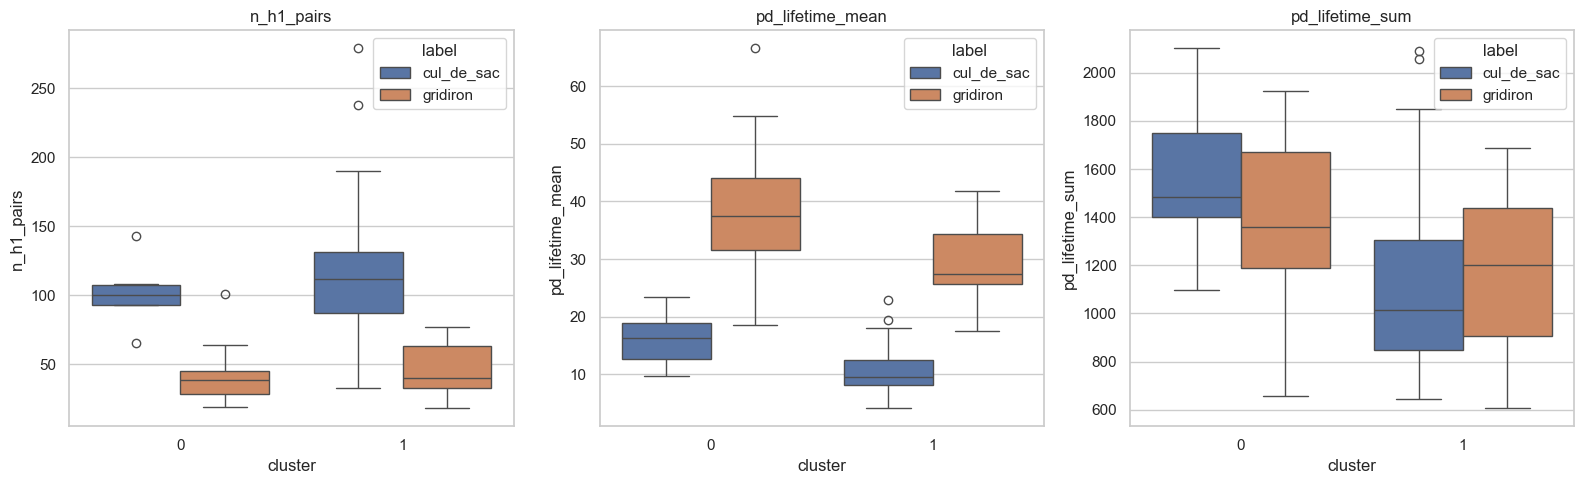

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, ['n_h1_pairs', 'pd_lifetime_mean', 'pd_lifetime_sum']):
    sns.boxplot(data=meta_features, x='cluster', y=col, hue='label', ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

## 7. Optional: Diagram-Distance Clustering if TDA Distance Libraries Are Installed

The literature workflow you described often clusters directly from pairwise bottleneck or Wasserstein distances between persistence diagrams, then visualizes those distances with t-SNE/MDS. This environment currently may not have `gudhi` or `persim` installed. If you install one of them, this cell can be extended to compute exact diagram distances.

For this notebook, landscapes are the default because they are already available, fixed-length, fast, and stable. Average-linkage clustering on PCA-reduced persistence landscape coordinates is a reasonable unsupervised analogue when exact bottleneck/Wasserstein distance computation is unavailable.


In [15]:
try:
    import gudhi  # noqa: F401
    print('gudhi is installed. You can add bottleneck/Wasserstein diagram-distance clustering here.')
except Exception:
    print('gudhi is not installed in this environment; using PCA-space persistence-landscape clustering above.')

try:
    import persim  # noqa: F401
    print('persim is installed. You can add persim.bottleneck / persim.wasserstein comparisons here.')
except Exception:
    print('persim is not installed in this environment; using PCA-space persistence-landscape clustering above.')

gudhi is installed. You can add bottleneck/Wasserstein diagram-distance clustering here.
persim is not installed in this environment; using PCA-space persistence-landscape clustering above.


## 8. Save Cluster Assignments

In [16]:
output_cols = [
    'sample', 'city', 'label', 'cluster', 'cluster_interpreted_as', 'matches_folder_label',
    'n_h1_pairs', 'x_max', 'pd_lifetime_mean', 'pd_lifetime_max', 'pd_lifetime_sum',
    'pca1', 'pca2', 'tsne1', 'tsne2'
]
assignments = viz.merge(
    meta_features[['sample', 'cluster_interpreted_as', 'matches_folder_label']],
    on='sample',
    how='left',
)
assignments[output_cols].to_csv(ASSIGNMENTS_OUT, index=False)
print(f'Wrote {ASSIGNMENTS_OUT.resolve()}')
display(assignments[output_cols].head())

Wrote /Users/gregorioperez/Documents/Maestria/Investigacion/levelset_urban/notebooks/cluster_us_city_persistence_landscapes_pca_space_assignments.csv


,sample,city,label,cluster,cluster_interpreted_as,matches_folder_label,n_h1_pairs,x_max,pd_lifetime_mean,pd_lifetime_max,pd_lifetime_sum,pca1,pca2,tsne1,tsne2
0,cary_town_cul_de_sac_12,cary_town,cul_de_sac,1,cul_de_sac,True,238,124.9,4.136134,50.5,984.4,0.462679,-0.165335,0.250322,-4.439176
1,cary_town_cul_de_sac_13,cary_town,cul_de_sac,1,cul_de_sac,True,181,109.1,8.625414,87.8,1561.2,0.252581,0.284762,-2.212170,-3.880072
2,cary_town_cul_de_sac_14,cary_town,cul_de_sac,0,gridiron,False,143,51.3,9.718182,40.9,1389.7,-0.363220,-0.130178,4.750632,0.540302
3,cary_town_cul_de_sac_16,cary_town,cul_de_sac,1,cul_de_sac,True,190,108.5,8.451579,108.5,1605.8,0.299958,0.240280,-1.606256,-3.395937
4,cary_town_cul_de_sac_18,cary_town,cul_de_sac,1,cul_de_sac,True,97,95.9,8.249485,89.2,800.2,0.349875,0.414402,-2.813482,-4.904147


## Notes

- The clustering is unsupervised. Folder labels are used only after clustering to interpret and validate the two groups.
- The strongest preprocessing choice is resampling and amplitude-normalizing the landscapes. Without this, the saved landscape vectors mix topology with sample-specific filtration scale.
- The final cluster labels come from average-linkage hierarchical clustering on PCA-reduced H1 landscape vectors.
- t-SNE is used only to visualize the PCA-space clustering, not to define cluster distances.
- If exact bottleneck/Wasserstein distances are required for a paper-style replication, install `gudhi` or `persim` and replace the landscape/PCA clustering with a pairwise diagram-distance matrix computed from `h1_pairs.csv`.
